# QM9 Dataset

Notebook to check the QM9WithRDKitMetrics dataset.

In [31]:
import torch
from torch_geometric.data import InMemoryDataset, Data
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from collections import Counter
import random
from tqdm.notebook import tqdm

from topoflow.data.graphs import QM9WithRDKitMetrics

In [32]:
# --- Load your dataset ---
# Option 1: Use the DummyMolecularDataset (for demonstration if you don't have your dataset ready)
path = "../data/QM9_RDKit/"
dataset = QM9WithRDKitMetrics(path)
print(f"Loaded dataset with {len(dataset)} molecules.")

# Option 2: Uncomment and use your actual QM9WithRDKitMetrics dataset
# Make sure your 'topoflow' package is installed in editable mode or available on PYTHONPATH
# from topoflow.data.graphs.datasets import QM9WithRDKitMetrics
# dataset = QM9WithRDKitMetrics(root='data/QM9_RDKit')
# print(f"Loaded QM9WithRDKitMetrics Dataset with {len(dataset)} molecules.")

print(f"First molecule's x shape: {dataset[0].x.shape}")
print(f"First molecule's y shape: {dataset[0].y.shape}")

# Set plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12


/home/marco/Documents/phd/topoFlow/topoflow/data/graphs/datasets.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.data, self.slices = torch.load(self.processed_path

Loaded dataset with 129012 molecules.
First molecule's x shape: torch.Size([5, 8])
First molecule's y shape: torch.Size([3])


In [33]:
atom_labels = ['H', 'C', 'N', 'O', 'F']
num_atoms_list = []
all_atom_types_one_hot = []
all_coords = []
all_y_scores = []
for data in dataset:
    num_atoms_list.append(data.x.shape[0])
    
    # Assuming the first 5 features of data.x are one-hot encodings of atom types
    atom_type_features = data.x[:, :5]
    all_atom_types_one_hot.append(atom_type_features)
    
    # Assuming the last 3 features of data.x are the 3D positions
    all_coords.append(data.x[:, 5:8]) # Slicing for positions
    
    all_y_scores.append(data.y)

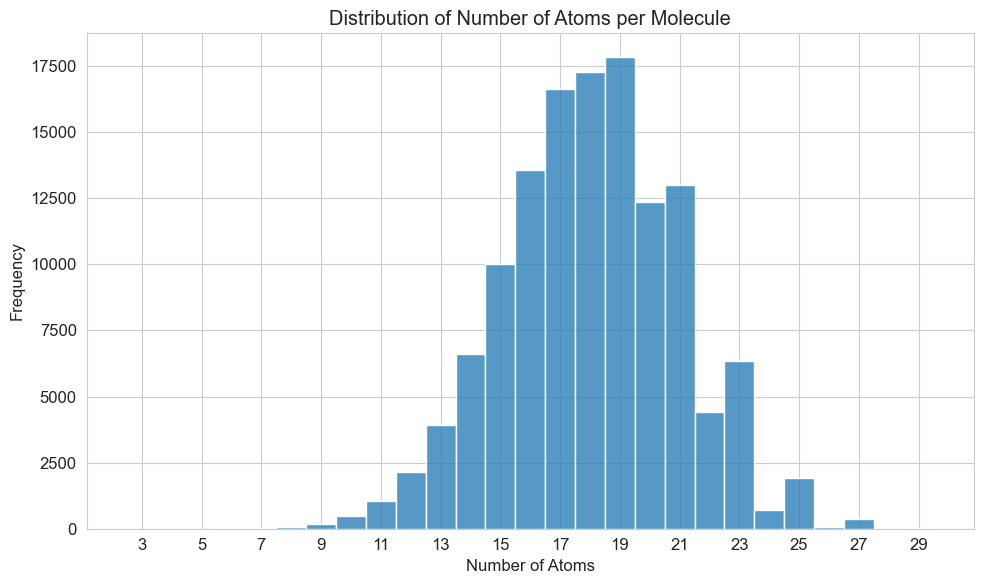

In [34]:
plt.figure(figsize=(10, 6))
sns.histplot(num_atoms_list, bins=np.arange(min(num_atoms_list), max(num_atoms_list) + 2) - 0.5)
plt.title('Distribution of Number of Atoms per Molecule')
plt.xlabel('Number of Atoms')
plt.ylabel('Frequency')
plt.xticks(np.arange(min(num_atoms_list), max(num_atoms_list) + 1, 2)) # Adjust x-ticks for better readability
plt.tight_layout()
plt.show()

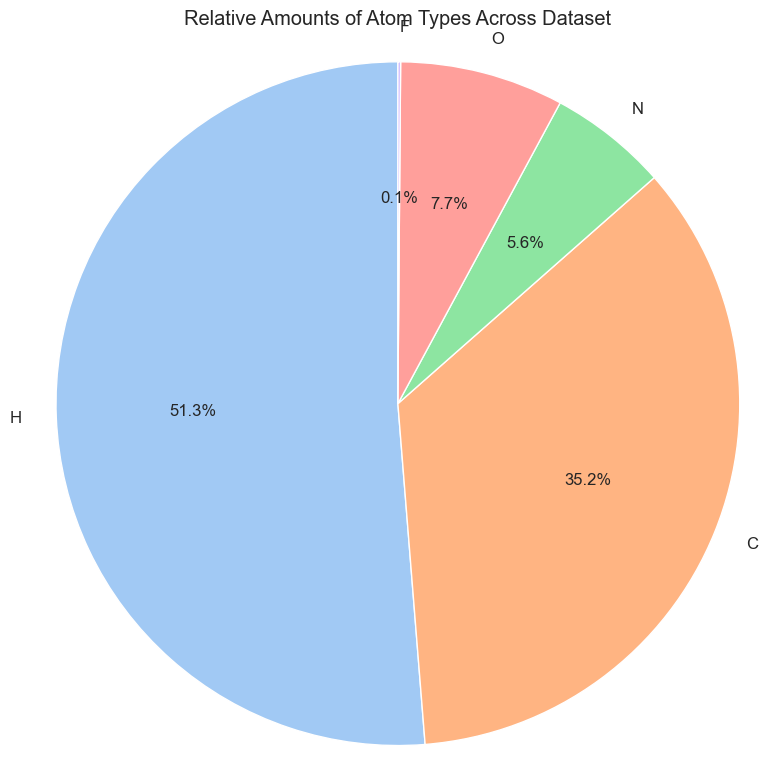

In [35]:
# Concatenate all atom type features from all molecules
all_atom_types_one_hot_cat = torch.cat(all_atom_types_one_hot, dim=0)

# Sum up the one-hot vectors to get total counts for each atom type
atom_counts = all_atom_types_one_hot_cat.sum(dim=0).numpy()

# Plotting
plt.figure(figsize=(8, 8))
plt.pie(atom_counts, labels=atom_labels, autopct='%1.1f%%', startangle=90, colors=sns.color_palette("pastel"))
plt.title('Relative Amounts of Atom Types Across Dataset')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.tight_layout()
plt.show()

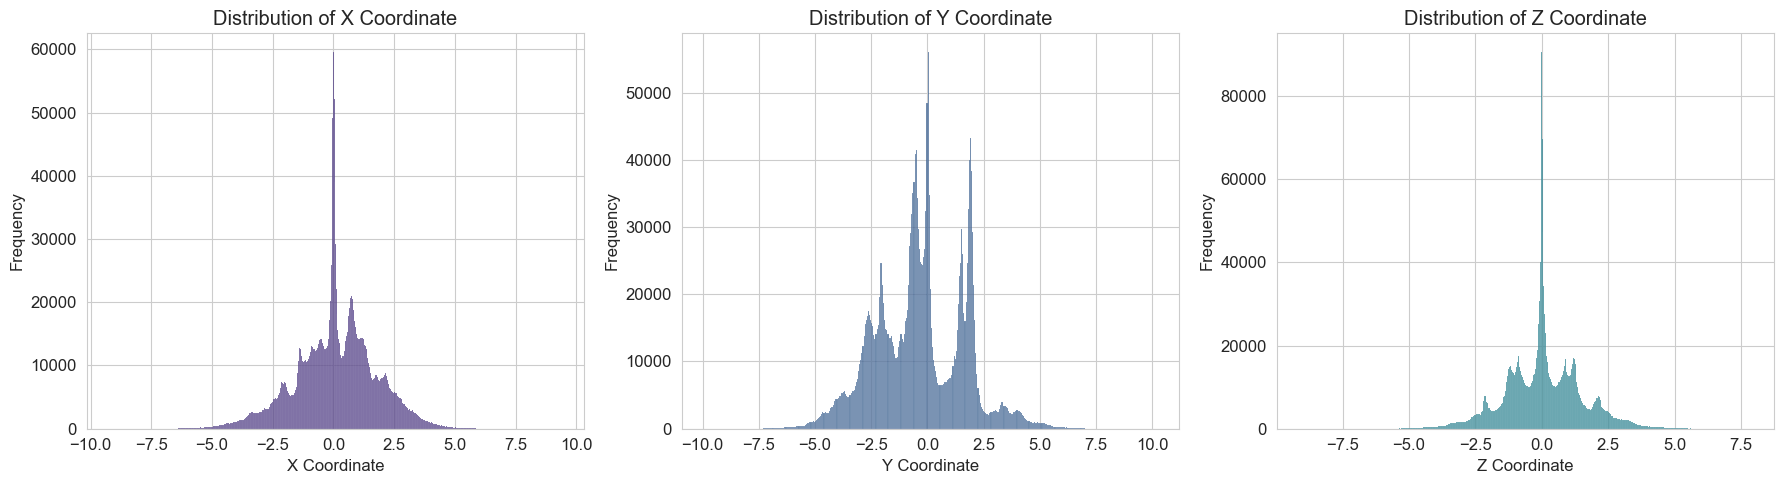

In [36]:
all_coords_cat = torch.cat(all_coords, dim=0).numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
coord_labels = ['X Coordinate', 'Y Coordinate', 'Z Coordinate']

for i, ax in enumerate(axes):
    sns.histplot(all_coords_cat[:, i], ax=ax, color=sns.color_palette("viridis")[i])
    ax.set_title(f'Distribution of {coord_labels[i]}')
    ax.set_xlabel(coord_labels[i])
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

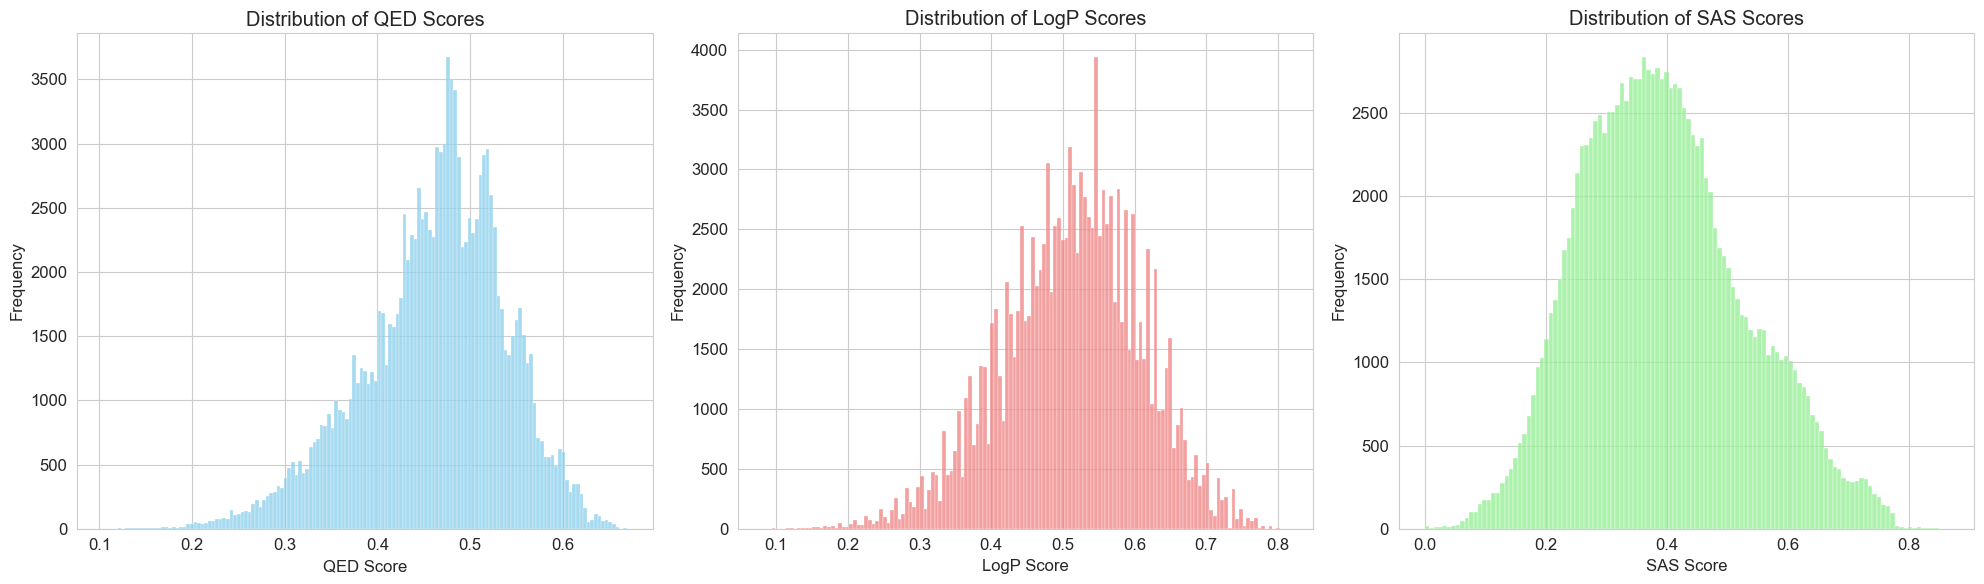

In [37]:
all_y_scores_cat = torch.stack(all_y_scores).numpy()

# Extract individual scores
qed_scores = all_y_scores_cat[:, 0]
logp_scores = all_y_scores_cat[:, 1]
sas_scores = all_y_scores_cat[:, 2]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# QED Distribution
sns.histplot(qed_scores, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of QED Scores')
axes[0].set_xlabel('QED Score')
axes[0].set_ylabel('Frequency')

# LogP Distribution
sns.histplot(logp_scores, ax=axes[1], color='lightcoral')
axes[1].set_title('Distribution of LogP Scores')
axes[1].set_xlabel('LogP Score')
axes[1].set_ylabel('Frequency')

# SAS Distribution
sns.histplot(sas_scores, ax=axes[2], color='lightgreen')
axes[2].set_title('Distribution of SAS Scores')
axes[2].set_xlabel('SAS Score')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()